# Model 2: YOLOv8 Classification (YOLOv8n-cls)
ARTI 502 Final Project, Traffic Sign Recognition (GTSRB)

Same split as the dataset notebook (Member 2): 80/20 track-based split, seed 42, official test set.

On Kaggle: Settings > Accelerator > GPU T4 x2, and Settings > Internet > On.

## 1. Install and check GPU

In [8]:
!pip install -q ultralytics
import torch
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

GPU: True Tesla T4


## 2. Imports and seed

In [9]:
import os, time, random, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
NUM_CLASSES = 43

## 3. Load the dataset and rebuild the shared split (same code as the dataset notebook)

In [10]:
dataset_dir = Path("/kaggle/input/gtsrb-german-traffic-sign")
if not (dataset_dir / "Train.csv").exists():
    import kagglehub
    dataset_dir = Path(kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"))

train = pd.read_csv(dataset_dir / "Train.csv")
train["TrackGroup"] = train["Path"].str.extract(r"/(\d+_\d+)_\d+\.png$", expand=False)
tracks = train[["TrackGroup", "ClassId"]].drop_duplicates()
train_tracks, val_tracks = train_test_split(tracks, test_size=0.20, random_state=SEED, stratify=tracks["ClassId"])
train_df = train[train["TrackGroup"].isin(train_tracks["TrackGroup"])].copy()
val_df = train[train["TrackGroup"].isin(val_tracks["TrackGroup"])].copy()
test_df = pd.read_csv(dataset_dir / "Test.csv")

print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
# Expected: Train 31,350 | Validation 7,859 | Test 12,630

Train: 31,350 | Validation: 7,859 | Test: 12,630


## 4. Arrange the split in YOLO's folder format
YOLO classification reads `train/<class>/` and `val/<class>/` folders. Class folders are zero-padded (00 to 42) so their order matches the class IDs. Files are linked, not copied.

In [11]:
DATA = Path("/kaggle/working/yolo_data")
if DATA.exists(): shutil.rmtree(DATA)

def link_split(df, split):
    for c in range(NUM_CLASSES):
        (DATA / split / f"{c:02d}").mkdir(parents=True, exist_ok=True)
    for _, r in df.iterrows():
        src = dataset_dir / r["Path"]
        dst = DATA / split / f"{int(r['ClassId']):02d}" / Path(r["Path"]).name
        os.symlink(src, dst)

link_split(train_df, "train")
link_split(val_df, "val")
print("train:", sum(1 for _ in (DATA/"train").rglob("*.png")), "| val:", sum(1 for _ in (DATA/"val").rglob("*.png")))

train: 31350 | val: 7859


## 5. Build and train the model
YOLOv8n-cls pretrained on ImageNet; its classification head is replaced with a 43-class head automatically. Images are resized to 128×128.

In [12]:
from ultralytics import YOLO

IMGSZ, EPOCHS, BATCH = 128, 15, 32
model = YOLO("yolov8n-cls.pt")

t0 = time.time()
model.train(data=str(DATA), imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH, seed=SEED,fliplr=0.0,
            optimizer="Adam", lr0=1e-3, patience=5, project="/kaggle/working/runs", name="yolo_cls",
            exist_ok=True, plots=False, verbose=True)
training_minutes = (time.time() - t0) / 60
print(f"Total training time: {training_minutes:.1f} min")

RUN = Path("/kaggle/working/runs/yolo_cls")
model = YOLO(RUN / "weights/best.pt")
n_params = sum(p.numel() for p in model.model.parameters())
print("Parameters:", f"{n_params:,}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_data, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_cls, nbs=64, nms=None, opset=None, optimize=False, opt

## 6. Training curves

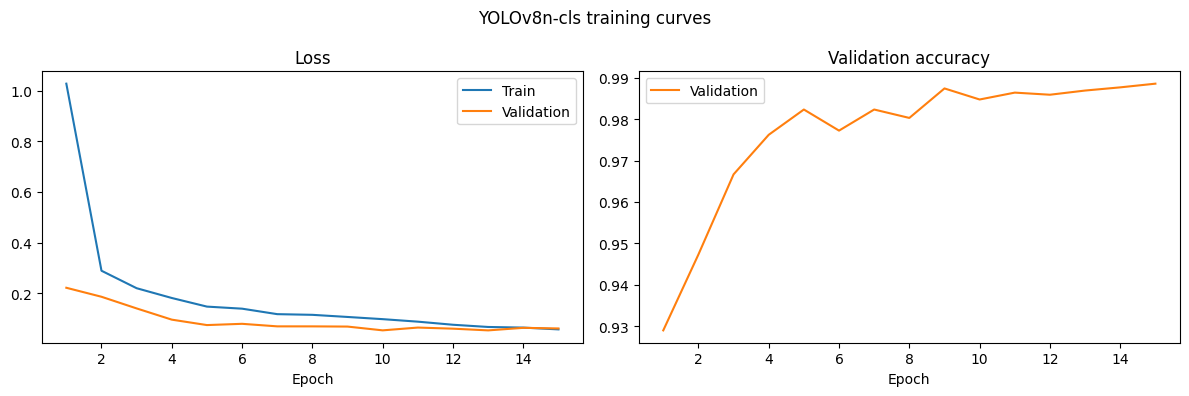

In [13]:
log = pd.read_csv(RUN / "results.csv"); log.columns = log.columns.str.strip()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(log["epoch"], log["train/loss"], label="Train"); ax[0].plot(log["epoch"], log["val/loss"], label="Validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(log["epoch"], log["metrics/accuracy_top1"], label="Validation", color="tab:orange")
ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.suptitle("YOLOv8n-cls training curves"); plt.tight_layout(); fig_curves = fig; plt.show()

## 7. Prediction helper

In [14]:
names = model.names  # index -> folder name ("00".."42")
order = [int(names[i]) for i in range(len(names))]  # index -> ClassId

def predict(df):
    paths = [str(dataset_dir / p) for p in df["Path"]]
    probs = np.zeros((len(paths), NUM_CLASSES), dtype=np.float32)
    for s in range(0, len(paths), 256):
        for j, r in enumerate(model.predict(paths[s:s+256], imgsz=IMGSZ, verbose=False)):
            probs[s + j, order] = r.probs.data.cpu().numpy()
    return probs

## 8. Initial results on the validation set (Table 5)

In [15]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

y_val = val_df["ClassId"].to_numpy()
p_val = predict(val_df).argmax(1)
acc = accuracy_score(y_val, p_val)
prec, rec, f1, _ = precision_recall_fscore_support(y_val, p_val, average="macro", zero_division=0)

results = pd.DataFrame({
    "Measure": ["Accuracy (%)", "Precision (macro)", "Recall (macro)", "F1-score (macro)", "Training time (min)"],
    "YOLOv8n-cls": [round(acc*100, 2), round(prec, 4), round(rec, 4), round(f1, 4), round(training_minutes, 1)],
})
display(results)
print(classification_report(y_val, p_val, digits=4, zero_division=0))

,Measure,YOLOv8n-cls
0,Accuracy (%),98.8500
1,Precision (macro),0.9883
2,Recall (macro),0.9891
3,F1-score (macro),0.9882
4,Training time (min),13.4000


              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        30
           1     1.0000    1.0000    1.0000       450
           2     0.9868    0.9956    0.9912       450
           3     1.0000    0.8889    0.9412       270
           4     0.9949    1.0000    0.9974       390
           5     0.9205    0.9972    0.9573       360
           6     0.9890    1.0000    0.9945        90
           7     1.0000    0.9800    0.9899       300
           8     0.9778    0.9778    0.9778       270
           9     1.0000    1.0000    1.0000       300
          10     1.0000    1.0000    1.0000       390
          11     0.9890    1.0000    0.9945       270
          12     1.0000    0.9976    0.9988       420
          13     1.0000    1.0000    1.0000       450
          14     1.0000    1.0000    1.0000       150
          15     1.0000    1.0000    1.0000       120
          16     0.9890    1.0000    0.9945        90
          17     1.0000    

## 9. Test set + save files (Member 6's format)
Download everything in /kaggle/working (except yolo_data and runs) from the Output panel and upload to the shared Drive folder.

In [16]:
BASE = Path("/kaggle/working"); NAME = "model2"

probs = predict(test_df)
y_true = test_df["ClassId"].to_numpy()
y_pred = probs.argmax(1)

pd.DataFrame({"y_true": y_true, "y_pred": y_pred}).to_csv(BASE / f"{NAME}_preds.csv", index=False)
np.save(BASE / f"{NAME}_probs.npy", probs)
shutil.copy(RUN / "weights/best.pt", BASE / f"{NAME}.pt")
results.to_csv(BASE / f"{NAME}_initial_val_results.csv", index=False)
fig_curves.savefig(BASE / f"{NAME}_training_curves.png", dpi=150)
print("Saved", NAME, "| test accuracy:", (y_pred == y_true).mean())
print("Parameters:", n_params, "| training time (min):", round(training_minutes, 1))

Saved model2 | test accuracy: 0.9890736342042755
Parameters: 1493371 | training time (min): 13.4


## 10. Confusion matrix and sample predictions

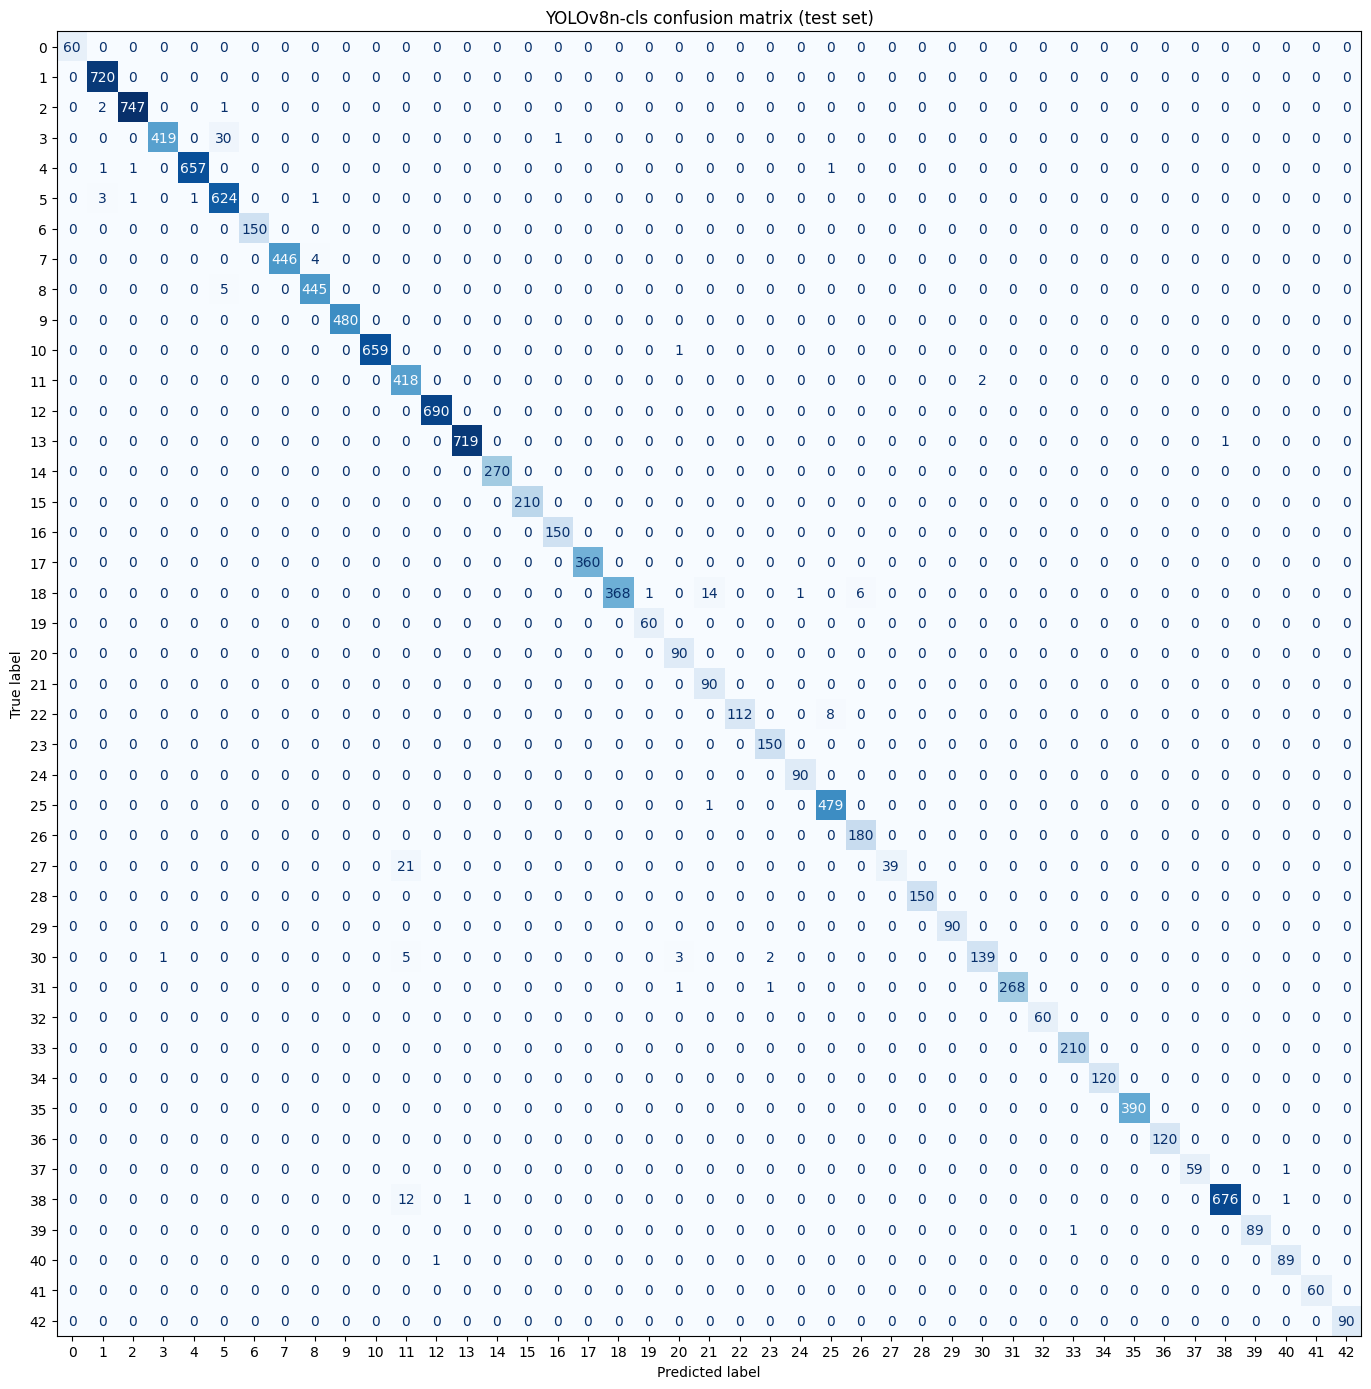

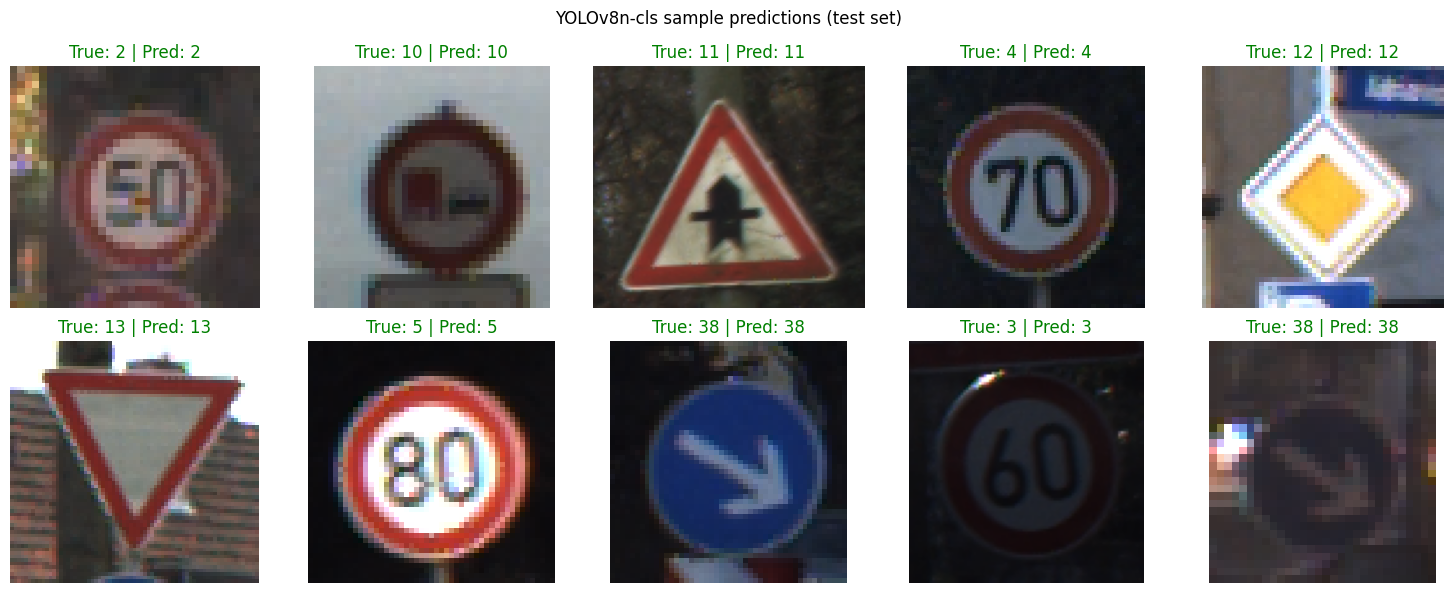

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, ax=ax, colorbar=False, cmap="Blues")
ax.set_title("YOLOv8n-cls confusion matrix (test set)")
plt.tight_layout(); fig.savefig(BASE / f"{NAME}_confusion_matrix.png", dpi=150); plt.show()

idx = np.random.RandomState(42).choice(len(test_df), 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, i in zip(axes.flat, idx):
    ax.imshow(plt.imread(dataset_dir / test_df.iloc[i]["Path"])); ax.axis("off")
    ax.set_title(f"True: {y_true[i]} | Pred: {y_pred[i]}", color="green" if y_pred[i] == y_true[i] else "red")
plt.suptitle("YOLOv8n-cls sample predictions (test set)")
plt.tight_layout(); fig.savefig(BASE / f"{NAME}_sample_predictions.png", dpi=150); plt.show()